# 6.3 Событийный и пошаговый методы

# 6.3 事件驱动与固定时间步长方法

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4), "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#D55E00", "#009E73"]),
    "figure.dpi": 110,
})

Matplotlib is building the font cache; this may take a moment.


## Двухскоростная gray-модель
Частица входит слева с направлением +1. После каждого рассеяния новое направление выбирается из −1 и +1 с равными вероятностями, включая прежнее направление. Границы поглощают выходящие частицы.

В расчёте $x^*=x/(v\tau)$, $t^*=t/\tau$, $L^*=L/(v\tau)$. Скорость равна ±1, среднее время между событиями равно 1. Это учебная модель с постоянными свойствами, без спектра реального материала.

## 双速度 gray 模型
粒子从左侧以 +1 方向进入。每次散射后，以相同概率从 −1 和 +1 中重新选择方向，也可能保持原方向。粒子到达边界后被吸收。

计算采用 $x^*=x/(v\tau)$、$t^*=t/\tau$、$L^*=L/(v\tau)$，速度为 ±1，平均事件间隔为 1。这是参数恒定的教学模型，不包含真实材料的声子谱。

## Событийный расчёт
Тот же алгоритм приведён здесь полностью, чтобы Notebook выполнялся независимо.

## 事件驱动计算
这里完整保留同一算法，使本 Notebook 可以独立运行。

In [2]:
def event_transport(n, length, rng, n_cells=0):
    x = np.zeros(n)
    direction = np.ones(n)
    alive = np.ones(n, dtype=bool)
    transmitted = np.zeros(n, dtype=bool)
    elapsed = np.zeros(n)
    collisions = np.zeros(n, dtype=int)
    edges = np.linspace(0, length, n_cells + 1)
    residence = np.zeros(n_cells)
    signed_residence = np.zeros(n_cells)
    updates = 0
    while alive.any():
        ids = np.flatnonzero(alive)
        ts = rng.exponential(1.0, ids.size)
        tb = np.where(direction[ids] > 0, length - x[ids], x[ids])
        h = np.minimum(ts, tb)
        old_x = x[ids].copy()
        new_x = np.clip(old_x + direction[ids] * h, 0, length)
        if n_cells:
            lo = np.minimum(old_x, new_x)[:, None]
            hi = np.maximum(old_x, new_x)[:, None]
            overlap = np.maximum(0, np.minimum(hi, edges[1:])
                                 - np.maximum(lo, edges[:-1]))
            residence += overlap.sum(axis=0)
            signed_residence += (overlap * direction[ids, None]).sum(axis=0)
        elapsed[ids] += h
        x[ids] = new_x
        hit = tb <= ts
        transmitted[ids[hit]] = direction[ids[hit]] > 0
        alive[ids[hit]] = False
        scattered = ids[~hit]
        collisions[scattered] += 1
        direction[scattered] = rng.choice([-1.0, 1.0], scattered.size)
        updates += ids.size
    return {"transmitted": transmitted, "time": elapsed,
            "collisions": collisions, "x": x, "updates": updates,
            "residence": residence / n,
            "signed_residence": signed_residence / n}

## Фиксированный шаг
Сначала летим до конца шага или до границы. Для оставшихся частиц в конце шага проверяем рассеяние. Точная вероятность хотя бы одного события не устраняет погрешность такого порядка действий. Допуск в сравнении с границей нужен только для округления чисел.

## 固定步长
先飞行到步末或边界，再对尚未离开的粒子在步末判断散射。至少一次事件的概率虽然精确，但这种执行顺序仍会产生离散误差。边界判断中的容差仅用于浮点舍入。

In [3]:
def step_transport(n, length, dt, rng):
    x = np.zeros(n)
    direction = np.ones(n)
    alive = np.ones(n, dtype=bool)
    transmitted = np.zeros(n, dtype=bool)
    probability = -np.expm1(-dt)
    updates = 0
    while alive.any():
        ids = np.flatnonzero(alive)
        tb = np.where(direction[ids] > 0, length - x[ids], x[ids])
        hit = tb <= dt * (1 + 1e-12)
        h = np.minimum(tb, dt)
        x[ids] = np.clip(x[ids] + direction[ids] * h, 0, length)
        transmitted[ids[hit]] = direction[ids[hit]] > 0
        alive[ids[hit]] = False
        remain = ids[~hit]
        scatter = remain[rng.random(remain.size) < probability]
        direction[scatter] = rng.choice([-1.0, 1.0], scatter.size)
        updates += ids.size
    return {"transmitted": transmitted, "updates": updates, "x": x}

In [4]:
length = 5.0
N = 100_000
rng_event = np.random.default_rng(2026)
reference = event_transport(N, length, rng_event)
p_event = reference["transmitted"].mean()
se_event = np.sqrt(p_event * (1 - p_event) / N)
p_exact = 1 / (1 + length / 2)
step_sizes = np.array([1.0, 0.5, 0.2, 0.1, 0.05])
p_steps, se_steps, work_steps = [], [], []
for j, dt in enumerate(step_sizes):
    run = step_transport(N, length, dt, np.random.default_rng(3000 + j))
    p = run["transmitted"].mean()
    p_steps.append(p)
    se_steps.append(np.sqrt(p * (1 - p) / N))
    work_steps.append(run["updates"] / N)
p_steps = np.array(p_steps)
se_steps = np.array(se_steps)
work_steps = np.array(work_steps)
for dt, p, error, work in zip(step_sizes, p_steps, se_steps, work_steps):
    print(f"dt/tau={dt:.2f}: P={p:.6f}, SE={error:.6f}, updates/particle={work:.2f}")
print(f"Event: P={p_event:.6f}, SE={se_event:.6f}, theory={p_exact:.6f}")

dt/tau=1.00: P=0.353950, SE=0.001512, updates/particle=5.01
dt/tau=0.50: P=0.312140, SE=0.001465, updates/particle=9.96
dt/tau=0.20: P=0.292970, SE=0.001439, updates/particle=24.91
dt/tau=0.10: P=0.290440, SE=0.001436, updates/particle=50.09
dt/tau=0.05: P=0.287320, SE=0.001431, updates/particle=99.73
Event: P=0.284350, SE=0.001427, theory=0.285714


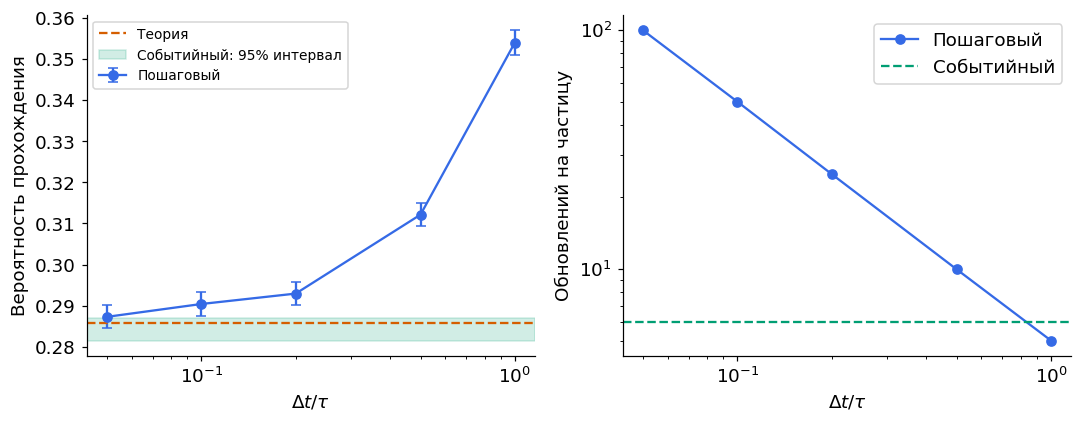

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].errorbar(step_sizes, p_steps, yerr=1.96 * se_steps,
                 fmt="o-", capsize=3, label="Пошаговый")
axes[0].axhline(p_exact, color="#D55E00", linestyle="--", label="Теория")
axes[0].axhspan(p_event - 1.96 * se_event, p_event + 1.96 * se_event,
               color="#009E73", alpha=0.18, label="Событийный: 95% интервал")
axes[0].set(xlabel=r"$\Delta t/\tau$", ylabel="Вероятность прохождения", xscale="log")
axes[0].legend(loc="upper left", fontsize=9)
axes[1].loglog(step_sizes, work_steps, "o-", label="Пошаговый")
axes[1].axhline(reference["updates"] / N, color="#009E73", linestyle="--", label="Событийный")
axes[1].set(xlabel=r"$\Delta t/\tau$", ylabel="Обновлений на частицу")
axes[1].legend()
fig.tight_layout()
plt.show()

## Два источника ошибки
Увеличение числа частиц уменьшает статистический шум, но не исправляет слишком большой шаг. В этом тесте при большом шаге алгоритм завышает прохождение: частица успевает дойти до границы до проверки рассеяния. Число обновлений служит счётчиком работы, а не измерением времени выполнения.

## 两类误差
增加粒子数可以降低统计噪声，但不能修正过大的时间步长。本测试中，大步长会高估透射率，因为粒子可能在检查散射前已经到达边界。更新次数用于比较工作量，不代表实际运行时间。

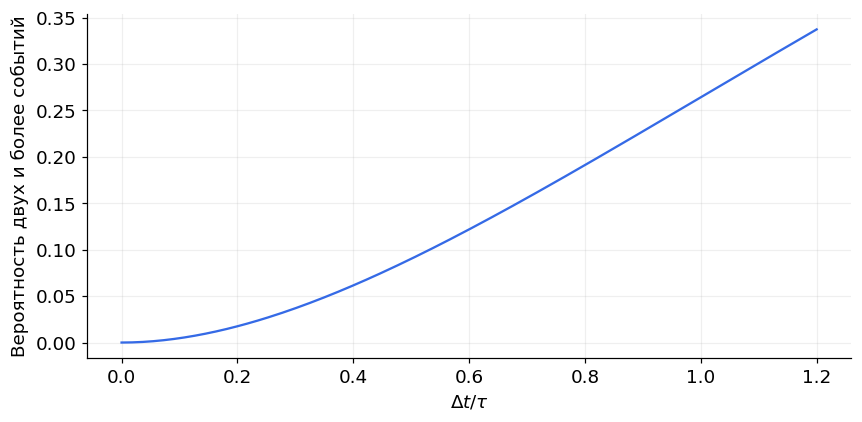

In [6]:
h = np.linspace(0, 1.2, 200)
p_multiple = 1 - np.exp(-h) * (1 + h)
fig, ax = plt.subplots()
ax.plot(h, p_multiple)
ax.set(xlabel=r"$\Delta t/\tau$", ylabel="Вероятность двух и более событий")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

## Попробуйте
Сначала уменьшите шаг, затем увеличьте $N$. Проверьте, какой источник ошибки преобладает в каждом случае. Все запуски заканчиваются выходом частиц, ограничения на число событий нет.

## 练习
先减小步长，再增加 $N$，判断各情况下哪种误差占主导。所有计算都在粒子离开边界后结束，不截断事件次数。